# Exploración reproducible: `spear_phish_mx`

Este notebook lee el CSV original sin modificarlo. El análisis completo se guarda en [`../reports/spear_phish_mx.md`](../reports/spear_phish_mx.md).

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
while not (HERE / 'notebooks' / 'exploracion-datasets' / 'dataset_audit.py').exists():
    if HERE.parent == HERE:
        raise FileNotFoundError('No se encontró la raíz del repositorio')
    HERE = HERE.parent
sys.path.insert(0, str(HERE / 'notebooks' / 'exploracion-datasets'))
from dataset_audit import DATASETS, analyze_dataset, load_dataset, combined_text
spec = next(item for item in DATASETS if item.slug == 'spear_phish_mx')
df = load_dataset(spec)
result = analyze_dataset(spec)
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Objetivo: {spec.target}')

Dimensiones: 3,006 filas × 17 columnas
Objetivo: etiqueta


## Esquema, tipos y nulos

In [2]:
schema = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'nulos_pct': (df.isna().mean() * 100).round(2),
})
display(schema)

,tipo,nulos,nulos_pct
hash,str,0,0.00
id_original,int64,0,0.00
etiqueta,int64,0,0.00
asunto,str,2,0.07
cuerpo_sanitizado,str,0,0.00
fecha,float64,3006,100.00
conteo_urls,int64,0,0.00
urls_desactivadas,str,0,0.00
dirigido_a_persona_v2,bool,0,0.00
destinatario_detectado_v2,str,283,9.41


## Clases, duplicados y conflictos

,registros
etiqueta,
1,1891
0,1115


Filas duplicadas: 0
Filas con texto repetido: 4
Textos con etiquetas conflictivas: 0


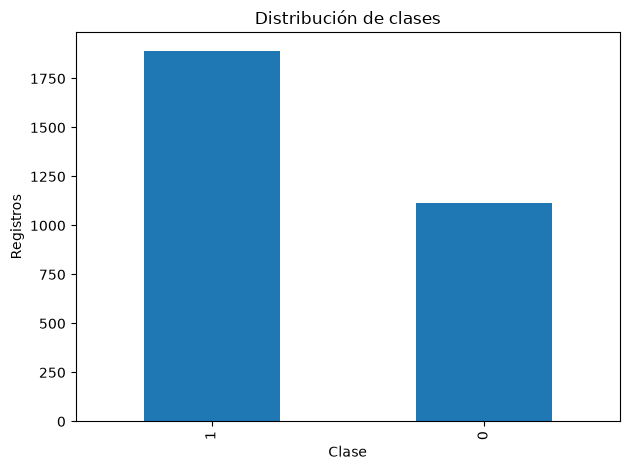

In [3]:
display(df[spec.target].value_counts(dropna=False).rename('registros').to_frame())
print('Filas duplicadas:', result['full_row_duplicates'])
print('Filas con texto repetido:', result['text_duplicates'])
print('Textos con etiquetas conflictivas:', result['conflicting_normalized_texts'])
df[spec.target].astype(str).value_counts().plot(kind='bar', title='Distribución de clases')
plt.xlabel('Clase'); plt.ylabel('Registros'); plt.tight_layout(); plt.show()

## Longitud, idioma y patrones

,caracteres,palabras
count,3006.000000,3006.000000
min,50.000000,6.000000
q25,254.000000,34.000000
median,433.000000,60.000000
mean,1011.358283,151.005323
q75,896.750000,135.750000
p95,3652.500000,550.000000
max,28478.000000,4178.000000


Idiomas declarados o estimados: {'es': 2916, 'indeterminado': 54, 'en': 36}
Filas con URL/correo/teléfono: 1928 4 304


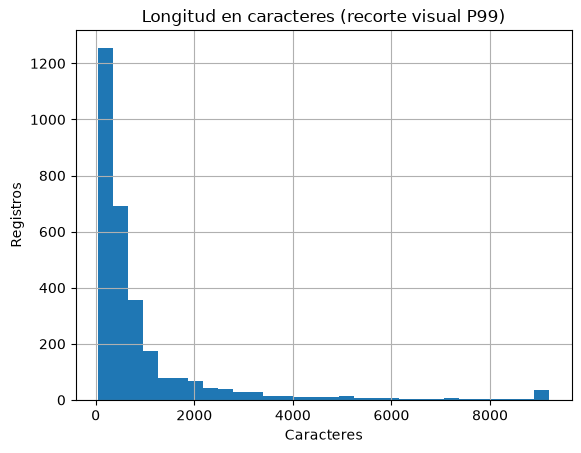

In [4]:
display(pd.DataFrame({
    'caracteres': result['length_characters'],
    'palabras': result['length_words'],
}))
print('Idiomas declarados o estimados:', result['declared_languages'] or result['language_heuristic'])
print('Filas con URL/correo/teléfono:', result['rows_with_url_pattern'], result['rows_with_email_pattern'], result['rows_with_phone_pattern'])
text = combined_text(df, spec.text_columns)
text.str.len().clip(upper=text.str.len().quantile(.99)).hist(bins=30)
plt.title('Longitud en caracteres (recorte visual P99)'); plt.xlabel('Caracteres'); plt.ylabel('Registros'); plt.show()

## Ejemplos sanitizados y conclusión

In [5]:
for label, examples in result['examples'].items():
    print(f'\nClase {label}')
    for example in examples:
        print('-', example)


Clase 0
- Maestria Hola Emanuel Ortega Carbajal, Nesti mira... donde trabajaba mike.... ¿Sabías que en la Unidad del CICESE en Tepic tenemos una maestría que pertenece al Sistema Nacional de Posgrado? ¿Que sus objetivos son "Formar recursos humanos altamente especializados con conocimiento…
- Missxtranger, Advertencia final: ¡tu cuenta de Netflix será eliminada! Hola Juan Galván Torres, ¡Continúa disfrutando de películas, programas de TV y más ilimitados! ¿Listo para mirar? N E T F L I X ¡Tu membresía ha caducado! Querido cliente, Su membresía ha caducado. Pero, como …

Clase 1
- Problema con Configuración de Load Balancer Hola Bernal Ramos García, Su configuración de load balancer presenta errores. Revisar settings en: hxxp://www[.]xmadwater[.]com[.]cn/js/?app=com-d3&us[.]battle[.]net/login/en/?ref=us[.]battle[.]net/d3/en/index Urgente - plazo 10 días. L…
- Oferta de Capacitación en Containers Estimado Herlindo De La Cruz Gómez, Programa especial de capacitación en tecnologías de con

La interpretación, riesgos de fuga, sesgos, utilidad para Random Forest y estrategia de combinación están documentados en [`../reports/spear_phish_mx.md`](../reports/spear_phish_mx.md).